
# Practical Lab 2
## Multivariate Linear Regression, Non-Parametric Models and Cross-Validation

### Student Information

**Student Name:** Sukhchain Singh  
**Student Number:** 9111541  
**Course:** Foundations of Machine Learning

---
  


## Introduction

In this lab, I will use machine learning to predict diabetes disease progression one year after baseline using the Scikit-Learn Diabetes dataset.

I will explore the dataset, examine relationships between different features, and compare several machine learning models to see which ones make better predictions.

The models will include polynomial regression, decision trees, and K-Nearest Neighbors (kNN). I will also review the Logistic Regression requirement because it is normally used for classification.

To evaluate the models, I will use R-squared (R²), Mean Absolute Error (MAE), and Mean Absolute Percentage Error (MAPE).

The goal is to understand how these models work, compare their performance on unseen data, and identify their strengths and limitations.

This is an educational prediction project. The results should not be used alone to make medical decisions.


In [1]:

# Check our Python environment and installed libraries
import sys
import numpy as np
import pandas as pd
import matplotlib
import seaborn as sns
import sklearn

print("===== ENVIRONMENT INFORMATION =====")
print("Python:", sys.version.split()[0])
print("Environment:", sys.executable)

print("\n===== LIBRARY VERSIONS =====")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-Learn:", sklearn.__version__)

print("\nEnvironment setup completed successfully!")


===== ENVIRONMENT INFORMATION =====
Python: 3.11.17
Environment: c:\Users\shain\miniconda3\envs\practical-lab-2\python.exe

===== LIBRARY VERSIONS =====
NumPy: 2.4.6
Pandas: 3.0.6
Matplotlib: 3.11.2
Seaborn: 0.13.2
Scikit-Learn: 1.9.1

Environment setup completed successfully!



## Part 1 — Data Understanding and Preparation

### 1. Get the Data

For this assignment, I am using the Diabetes dataset provided by Scikit-Learn. The dataset contains baseline measurements from patients and a numerical target representing disease progression one year after baseline.

I will first load the dataset and review its official description to understand the features, target variable, and structure before performing any analysis.

**Dataset Source:** Scikit-Learn `load_diabetes()`

**Prediction Target:** Disease progression one year after baseline.


In [2]:

# Import the dataset module from Scikit-Learn
from sklearn import datasets

# Load the diabetes dataset with Pandas support
diabetes = datasets.load_diabetes(as_frame=True)

# Read the official dataset description
print("===== OFFICIAL DATASET DESCRIPTION =====")
print(diabetes.DESCR)


===== OFFICIAL DATASET DESCRIPTION =====
.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Ea

In [3]:

# Separate input features and target
X = diabetes.data
y = diabetes.target

# Create one DataFrame containing features and target
df = diabetes.frame.copy()

# Inspect dataset structure
print("===== DATASET INFORMATION =====")
print("Total patients:", df.shape[0])
print("Total input features:", X.shape[1])
print("Feature names:", list(X.columns))
print("Target name:", y.name)

# Display the first five observations
print("\n===== FIRST FIVE ROWS =====")
display(df.head())

# Inspect data types
print("\n===== DATA TYPES =====")
print(df.dtypes)

# Inspect target values
print("\n===== TARGET INFORMATION =====")
print("Minimum progression score:", y.min())
print("Maximum progression score:", y.max())
print("Average progression score:", round(y.mean(), 2))
print("Number of zero target values:", (y == 0).sum())

# Examine the BMI feature
print("\n===== BMI INFORMATION =====")
print("Minimum BMI feature value:", X["bmi"].min())
print("Maximum BMI feature value:", X["bmi"].max())
print("Average BMI feature value:", round(X["bmi"].mean(), 4))


===== DATASET INFORMATION =====
Total patients: 442
Total input features: 10
Feature names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Target name: target

===== FIRST FIVE ROWS =====


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0



===== DATA TYPES =====
age       float64
sex       float64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target    float64
dtype: object

===== TARGET INFORMATION =====
Minimum progression score: 25.0
Maximum progression score: 346.0
Average progression score: 152.13
Number of zero target values: 0

===== BMI INFORMATION =====
Minimum BMI feature value: -0.09027529589850945
Maximum BMI feature value: 0.17055522598064407
Average BMI feature value: -0.0



### 2. Frame the Problem

#### 2.1 What am I trying to predict?

The goal of this project is to predict diabetes disease progression one year after baseline using patient measurements.

The dataset contains 442 observations and 10 input features, including age, sex, BMI, blood pressure, and six blood-related measurements.

The target is a numerical disease progression score.

#### 2.2 Type of Machine Learning Problem

This is a supervised learning problem because the dataset contains both input features (X) and known target values (y).

It is mainly a regression problem because we are predicting a continuous numerical value rather than a category such as Yes or No.

#### 2.3 Why Is This Problem Important?

Predicting disease progression could help researchers study patterns associated with higher progression scores.

However, this is an educational machine learning project. The predictions should not be used alone for medical diagnosis or treatment decisions.

#### 2.4 Why Compare Different Models?

I will compare polynomial regression, decision trees, and kNN regression to understand how different algorithms learn relationships in the data.

Polynomial regression uses a mathematical equation to model relationships. Decision trees learn decision rules, while kNN uses nearby observations to make predictions.

Comparing these models will help me understand which approaches perform better on this dataset.

#### 2.5 Training, Validation, and Testing

I will divide the dataset into:

- Training (75%): Used to train the models.
- Validation (10%): Used to compare models and select the best one.
- Testing (15%): Used to evaluate the selected model on unseen data.

Keeping these datasets separate helps reduce the risk of overfitting and gives a more realistic estimate of model performance.

#### 2.6 Evaluation Metrics

I will compare models using three regression metrics:

- R²: Measures how well the model explains variation in the target. Higher is generally better.
- MAE: Measures the average absolute difference between actual and predicted values. Lower is better.
- MAPE: Measures average absolute prediction error as a percentage of actual values. Lower is generally better.

I will check for zero target values before calculating MAPE because values near zero can make this metric unreliable.

Using multiple metrics gives a better understanding of model performance than relying on one metric alone.

#### 2.7 Connections to Previous Workshops

**Performance Metrics Classification Workshop**

In this workshop, I learned that a model can look successful according to one metric but perform poorly according to another. For this lab, I will apply the same lesson by comparing R², MAE, and MAPE rather than relying on a single score.

**K-Nearest Neighbors Workshop**

I learned that kNN makes predictions using nearby observations and that feature scaling matters because the algorithm uses distances. I also learned the importance of choosing suitable hyperparameters and preventing data leakage.

In this lab, I will use KNeighborsRegressor because the target is continuous.

**Logistic Regression Classifier Workshop**

This workshop helped me understand the difference between classification and regression. Logistic Regression uses a sigmoid function to estimate class probabilities.

Since our diabetes target is continuous, the Logistic Regression requirement needs clarification before implementation.

#### 2.8 Expected Outcome

By the end of the project, I want to identify a model that predicts diabetes progression reasonably well on unseen data.

I will also compare training and validation performance, examine prediction errors, and discuss the limitations of the selected model.

The results will show how effectively these algorithms learn patterns from this dataset, without claiming that they are clinically validated.



### 3. Exploratory Data Analysis (EDA)

#### 3.1 Dataset Structure and Descriptive Statistics

I will examine the dataset's statistical summary, missing values, and duplicate observations to understand the quality of the data before building machine learning models.

Descriptive statistics help me understand the range, average, and variation of each feature. These observations can also help identify unusual values that may affect model performance.


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display summary statistics
print("===== DESCRIPTIVE STATISTICS =====")
display(df.describe().T.round(3))

# Check missing values in every column
print("\n===== MISSING VALUES =====")
display(df.isnull().sum().to_frame("Missing Values"))

# Check for duplicate rows
print("\n===== DUPLICATE ROWS =====")
print("Number of duplicate rows:", df.duplicated().sum())

# Check data types
print("\n===== DATA TYPES =====")
display(df.dtypes.to_frame("Data Type"))


===== DESCRIPTIVE STATISTICS =====


,count,mean,std,min,25%,50%,75%,max
age,442.0,-0.000,0.048,-0.107,-0.037,0.005,0.038,0.111
sex,442.0,0.000,0.048,-0.045,-0.045,-0.045,0.051,0.051
bmi,442.0,-0.000,0.048,-0.090,-0.034,-0.007,0.031,0.171
bp,442.0,-0.000,0.048,-0.112,-0.037,-0.006,0.036,0.132
s1,442.0,-0.000,0.048,-0.127,-0.034,-0.004,0.028,0.154
s2,442.0,0.000,0.048,-0.116,-0.030,-0.004,0.030,0.199
s3,442.0,-0.000,0.048,-0.102,-0.035,-0.007,0.029,0.181
s4,442.0,-0.000,0.048,-0.076,-0.039,-0.003,0.034,0.185
s5,442.0,0.000,0.048,-0.126,-0.033,-0.002,0.032,0.134
s6,442.0,0.000,0.048,-0.138,-0.033,-0.001,0.028,0.136



===== MISSING VALUES =====


,Missing Values
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0



===== DUPLICATE ROWS =====
Number of duplicate rows: 0

===== DATA TYPES =====


,Data Type
age,float64
sex,float64
bmi,float64
bp,float64
s1,float64
s2,float64
s3,float64
s4,float64
s5,float64
s6,float64



#### 3.2 Distribution Analysis Using Histograms

I will use histograms to examine how the disease progression scores and input features are distributed.

This will help me identify whether values are concentrated around certain ranges, whether distributions are symmetric or skewed, and whether there are unusual observations.


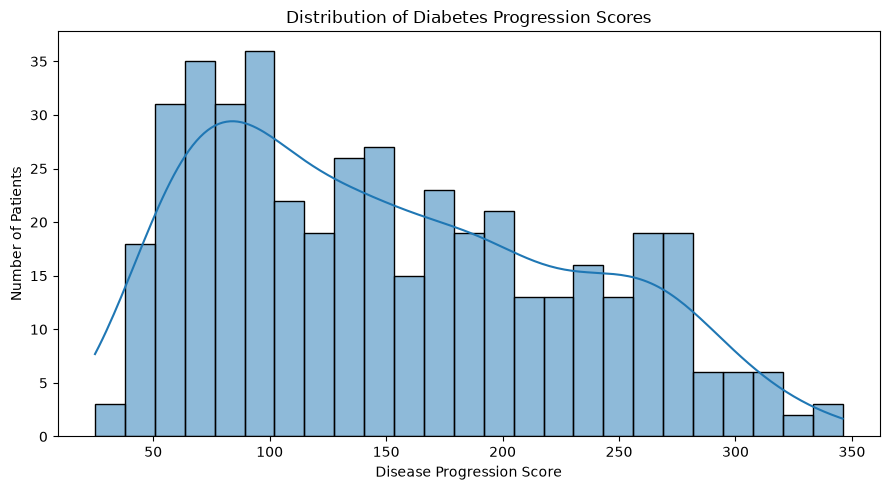

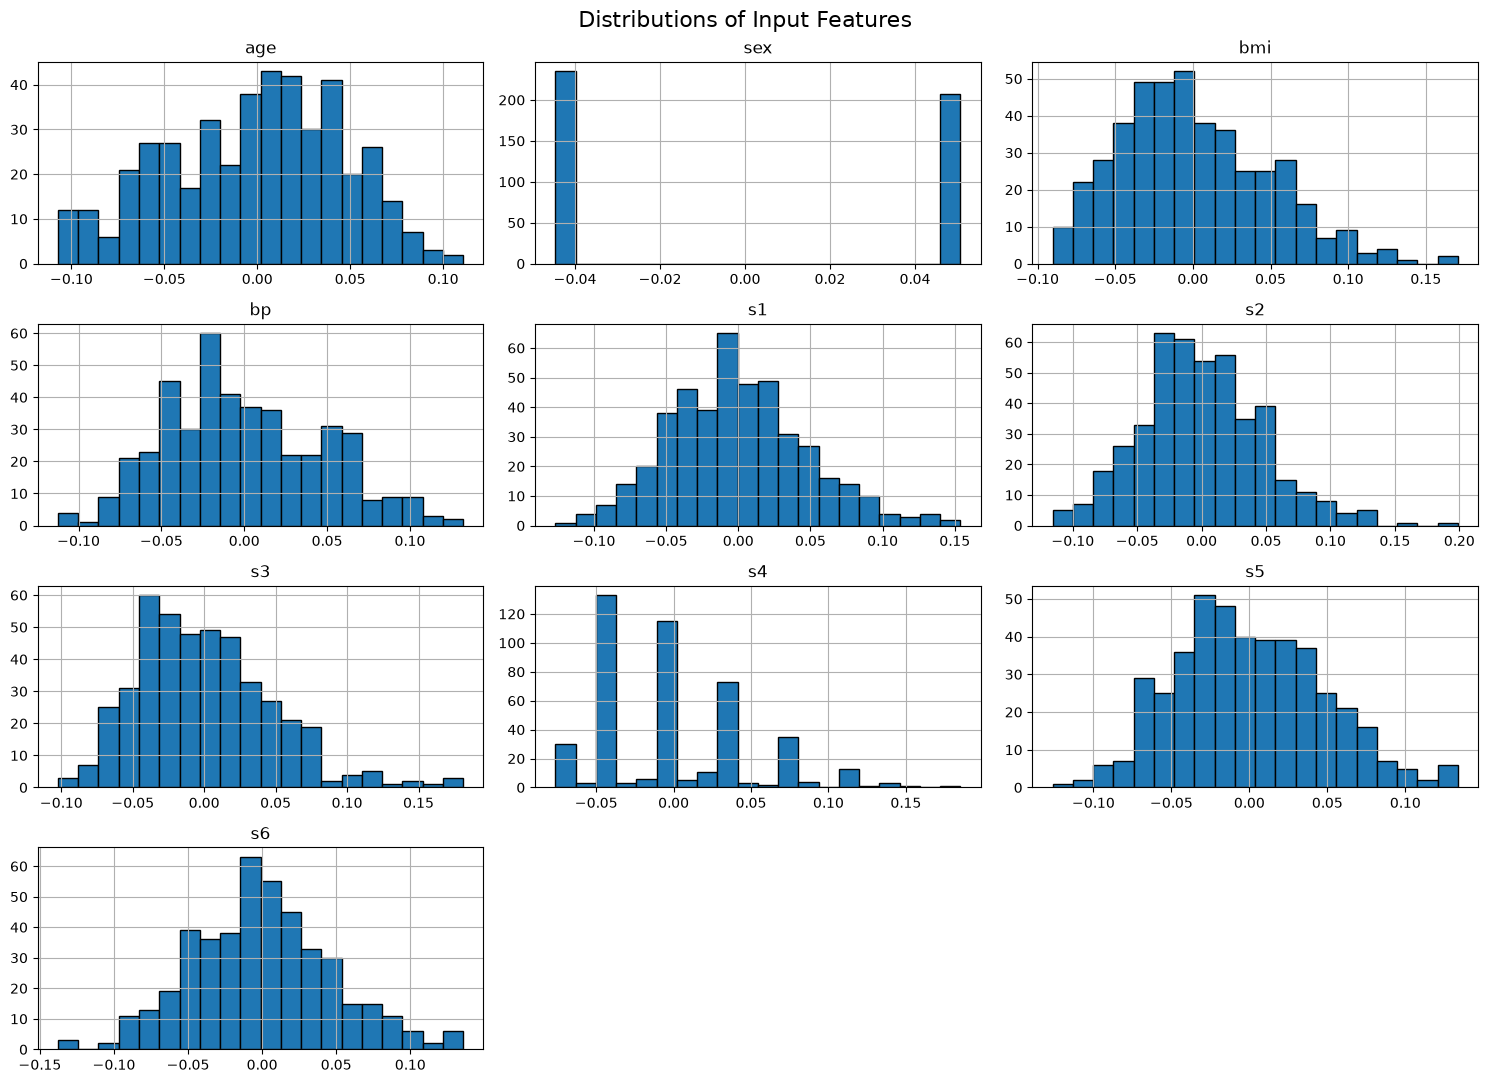

In [5]:

# Histogram of the target variable
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="target",
    bins=25,
    kde=True
)

plt.title("Distribution of Diabetes Progression Scores")
plt.xlabel("Disease Progression Score")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

# Histograms of all 10 input features
X.hist(
    figsize=(15, 11),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distributions of Input Features", fontsize=16)
plt.tight_layout()
plt.show()



#### 3.3 Scatter Plot Analysis

I will create scatter plots to explore how different patient measurements relate to disease progression.

I will focus on BMI, blood pressure, s5, and age. BMI is especially important because it will be used for the univariate polynomial regression models in Part 2.

These graphs will help me examine the direction, strength, and possible shape of the relationships.


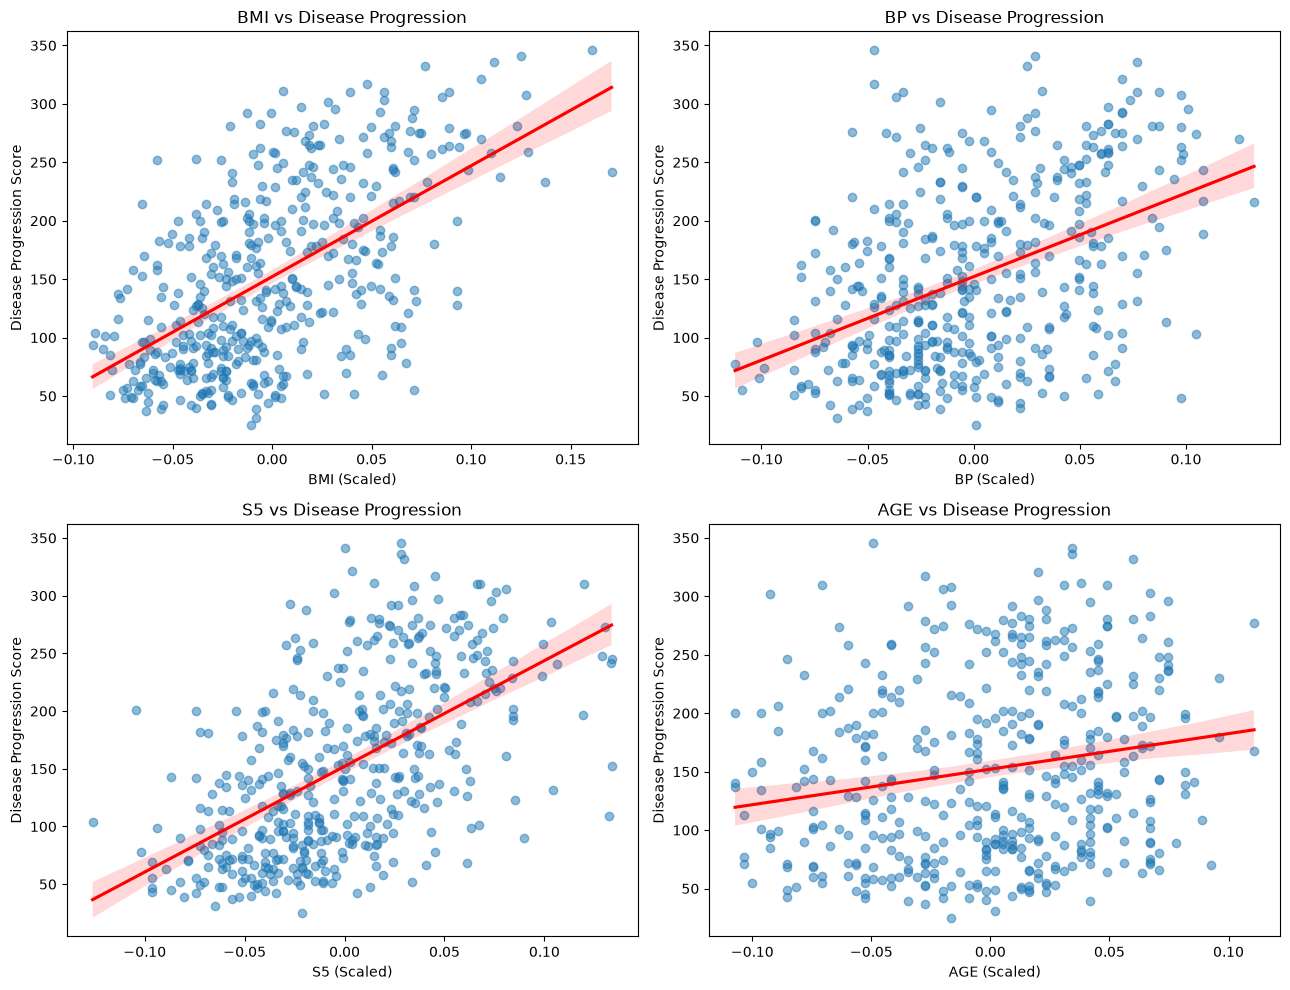

In [6]:

# Features selected for visual comparison
features_to_plot = ["bmi", "bp", "s5", "age"]

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, feature in zip(axes.flat, features_to_plot):

    sns.regplot(
        data=df,
        x=feature,
        y="target",
        ax=ax,
        scatter_kws={"alpha": 0.5},
        line_kws={"color": "red"}
    )

    ax.set_title(f"{feature.upper()} vs Disease Progression")
    ax.set_xlabel(f"{feature.upper()} (Scaled)")
    ax.set_ylabel("Disease Progression Score")

plt.tight_layout()
plt.show()



#### 3.4 Correlation Analysis

I will calculate a correlation matrix to measure the linear relationships between the numerical features and the disease progression target.

I will also create a heatmap to visualize these relationships and identify which features have stronger positive or negative correlations with the target.

These results will help me understand feature relationships before building multivariate models.


===== FEATURE CORRELATIONS WITH TARGET =====


,Correlation with Target
bmi,0.586
s5,0.566
bp,0.441
s4,0.430
s6,0.382
s1,0.212
age,0.188
s2,0.174
sex,0.043
s3,-0.395


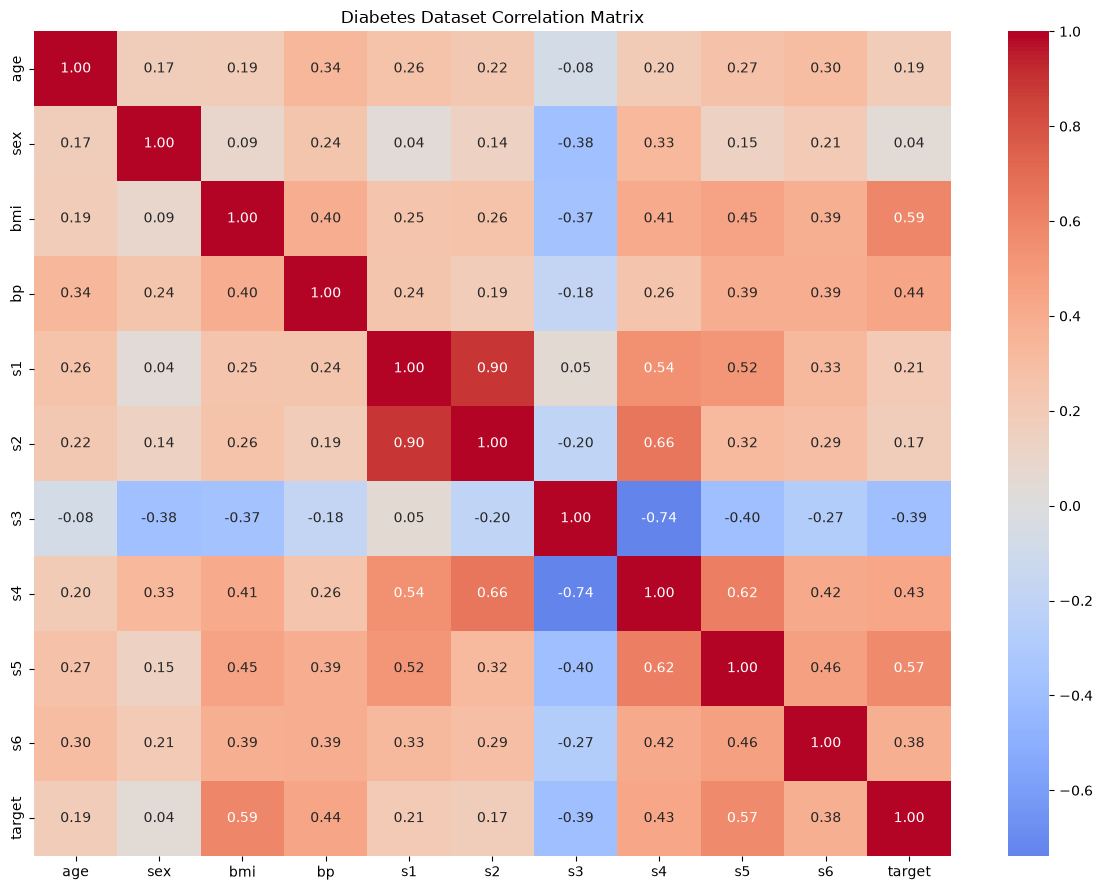

In [7]:

# Calculate Pearson correlation coefficients
correlation_matrix = df.corr()

# Display correlations with the target
print("===== FEATURE CORRELATIONS WITH TARGET =====")

target_correlations = correlation_matrix["target"].drop("target")

display(
    target_correlations
    .sort_values(ascending=False)
    .round(3)
    .to_frame("Correlation with Target")
)

# Create correlation heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Diabetes Dataset Correlation Matrix")
plt.tight_layout()
plt.show()



#### 3.5 EDA Insights

After exploring the diabetes dataset, I observed several patterns that may help with model selection.

**1. Dataset Quality**

The dataset contains 442 observations and 10 input features. I found no missing values or duplicate rows. All columns contain numerical data, so no data type conversion is required.

**2. Target Distribution**

The disease progression scores range from 25 to 346, with an average of 152.13. The histogram shows a wide distribution, with more observations at lower progression scores and a tail toward higher scores.

This suggests that predicting progression accurately for every patient may be challenging.

**3. Relationship Between BMI and Progression**

BMI has a positive correlation of approximately 0.59 with disease progression, making it one of the strongest relationships observed.

The scatter plot shows an upward trend, although the points are spread around the trend line. This suggests that higher scaled BMI values are generally associated with higher progression scores, but BMI alone cannot explain every patient's result.

**4. Other Important Features**

The s5 feature also shows a relatively strong positive correlation with progression (0.57).

Blood pressure has a moderate positive correlation (0.44), while age shows a weaker positive correlation (0.19).

The s3 feature has a negative correlation of approximately -0.39.

These results suggest that multiple features may provide useful information for predicting progression.

**5. Relationships Between Input Features**

I noticed that s1 and s2 have a very strong positive correlation of approximately 0.90. I also observed a strong negative correlation between s3 and s4 (-0.74).

This suggests that some features contain overlapping information, which may affect the stability and interpretation of certain models.

**6. Modeling Decisions**

Based on the EDA, I will use BMI for the univariate polynomial regression models, as required in Part 2.

For the multivariate models in Part 3, I will initially keep all 10 features because different features may provide additional predictive information. I will evaluate model performance before deciding whether any features should be removed.

I will also compare training and validation results to check whether more complex models improve predictions or begin to overfit.

**7. Limitations**

Correlation does not mean causation. The relationships observed in these graphs do not prove that a particular feature causes diabetes progression.

The dataset is also relatively small, and this educational analysis cannot establish whether a model is suitable for clinical use.



### 4. Data Cleaning

Before training the models, I checked the dataset for missing values, duplicates, invalid numerical values, and potential outliers.

I will not automatically remove extreme observations because they may represent genuine patient measurements. I will only modify the data if I find a justified reason to do so.


In [8]:

# Final data quality checks
print("===== DATA QUALITY CHECK =====")

print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Infinite values:", np.isinf(df.to_numpy()).sum())

# Identify possible extreme observations using IQR
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_counts = (
    (df < lower_bound) | (df > upper_bound)
).sum()

print("\n===== POTENTIAL OUTLIERS =====")
display(outlier_counts.to_frame("Potential Outliers"))

print("\nOriginal dataset shape:", df.shape)


===== DATA QUALITY CHECK =====
Missing values: 0
Duplicate rows: 0
Infinite values: 0

===== POTENTIAL OUTLIERS =====


,Potential Outliers
age,0
sex,0
bmi,3
bp,0
s1,8
s2,7
s3,7
s4,2
s5,4
s6,9



Original dataset shape: (442, 11)



#### Data Cleaning Results and Decisions

After inspecting the dataset, I found no missing values, duplicate rows, or infinite values.

I also used the IQR method to identify potential outliers. The results showed 3 potential outliers in BMI, 8 in s1, 7 in s2, 7 in s3, 2 in s4, 4 in s5, and 9 in s6. No outliers were detected in the target using this method.

I decided not to remove these observations because the IQR method only identifies unusual values; it does not prove that the measurements are incorrect.

Removing these observations without a clear reason could cause us to lose useful patient information.

Therefore, I kept all 442 observations for modeling. No missing-value imputation, duplicate removal, or feature conversion was necessary.



### 5. Train-Validation-Test Split

I will divide the dataset into three separate groups:

- **Training (75%):** Used to train the models.
- **Validation (10%):** Used to compare model performance and select hyperparameters.
- **Testing (15%):** Reserved for final evaluation after model selection.

I will use random_state=42 so the split is reproducible.

Because the dataset contains 442 observations, the exact percentages cannot be represented using whole numbers of rows. I will use the nearest practical allocation.

The test dataset will remain unused during model selection to avoid data leakage.


In [9]:

from sklearn.model_selection import train_test_split

# Calculate the requested split sizes
total_rows = len(X)

test_rows = round(total_rows * 0.15)
validation_rows = round(total_rows * 0.10)

# Step 1: Separate the test set
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=test_rows,
    random_state=42
)

# Step 2: Separate training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=validation_rows,
    random_state=42
)

# Verify the split
print("===== DATASET SPLIT =====")

print(f"Total observations: {total_rows}")

print(
    f"Training: {len(X_train)} rows "
    f"({len(X_train)/total_rows*100:.2f}%)"
)

print(
    f"Validation: {len(X_val)} rows "
    f"({len(X_val)/total_rows*100:.2f}%)"
)

print(
    f"Testing: {len(X_test)} rows "
    f"({len(X_test)/total_rows*100:.2f}%)"
)


# Check that training, validation, and testing do not overlap

assert X_train.index.intersection(X_val.index).empty, \
    "Training and validation sets overlap!"

assert X_train.index.intersection(X_test.index).empty, \
    "Training and testing sets overlap!"

assert X_val.index.intersection(X_test.index).empty, \
    "Validation and testing sets overlap!"

# Check that input features match their target values
assert X_train.index.equals(y_train.index)
assert X_val.index.equals(y_val.index)
assert X_test.index.equals(y_test.index)

# Check that no observations were lost
assert (
    len(X_train) + len(X_val) + len(X_test)
    == len(df)
)

print("===== SPLIT VERIFICATION =====")
print("No overlapping observations: PASSED")
print("Features and targets correctly aligned: PASSED")
print("No observations lost: PASSED")

print("\nAll dataset split checks passed!")


===== DATASET SPLIT =====
Total observations: 442
Training: 332 rows (75.11%)
Validation: 44 rows (9.95%)
Testing: 66 rows (14.93%)
===== SPLIT VERIFICATION =====
No overlapping observations: PASSED
Features and targets correctly aligned: PASSED
No observations lost: PASSED

All dataset split checks passed!


## Object-Oriented Programming (OOP) Model Design

My professor required a separate OOP class for each model type. I created five reusable Python classes in the external `models/` folder rather than defining the classes inside the notebook.

- `UnivariatePolynomialModel` — six objects for degrees 0–5.
- `MultivariatePolynomialModel` — two objects for degrees 2 and 3.
- `DecisionTreeModel` — two objects for depths 3 and 8.
- `KNNModel` — two objects for k=3 and k=15.
- `LogisticClassificationModel` — two objects for C=0.1 and C=1.0.

Each class provides a constructor `__init__()` and the methods `fit()` and `predict()`. I create a model object, train it, and use it to predict with the same data split and metrics as before. The classification experiment remains separate from the regression task.


In [10]:
# IMPORT CUSTOM PYTHON OOP CLASSES FROM EXTERNAL .PY FILES
from models import (
    UnivariatePolynomialModel,
    MultivariatePolynomialModel,
    DecisionTreeModel,
    KNNModel,
    LogisticClassificationModel,
)

print("Successfully imported all five external OOP classes!")


Successfully imported all five external OOP classes!



## Part 2 — Univariate Polynomial Regression

### 6. Polynomial Regression Models (Degrees 0–5)

In this section, I will train six polynomial regression models using BMI as the only input feature.

The polynomial degrees will range from 0 to 5. I will compare how increasing model complexity affects training and validation performance.

Degree 0 predicts a constant value, degree 1 represents a straight-line relationship, and higher degrees allow increasingly flexible curves.

I will train the models using only the training data and evaluate them on the training and validation datasets.

The test dataset will remain untouched until I select the best model.


In [11]:
# PART 2: BMI-ONLY POLYNOMIAL REGRESSION WITH OOP

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_absolute_percentage_error
)

# For this section, we only use BMI as input
X_train_bmi = X_train[["bmi"]]
X_val_bmi = X_val[["bmi"]]

# MAPE requires special caution if the target is zero
assert (y_train != 0).all()
assert (y_val != 0).all()

poly_models = {}
poly_results = []

for degree in range(6):
    # Create a separate object from our custom Python class
    model = UnivariatePolynomialModel(degree=degree)
    model.fit(X_train_bmi, y_train)

    train_pred = model.predict(X_train_bmi)
    val_pred = model.predict(X_val_bmi)

    poly_results.append({
        "Degree": degree,
        "Train R2": r2_score(y_train, train_pred),
        "Val R2": r2_score(y_val, val_pred),
        "Train MAE": mean_absolute_error(y_train, train_pred),
        "Val MAE": mean_absolute_error(y_val, val_pred),
        "Train MAPE (%)": mean_absolute_percentage_error(
            y_train, train_pred
        ) * 100,
        "Val MAPE (%)": mean_absolute_percentage_error(
            y_val, val_pred
        ) * 100
    })
    poly_models[degree] = model

poly_comparison = pd.DataFrame(poly_results)
print("===== POLYNOMIAL MODEL COMPARISON =====")
display(poly_comparison.round(3))

===== POLYNOMIAL MODEL COMPARISON =====


,Degree,Train R2,Val R2,Train MAE,Val MAE,Train MAPE (%),Val MAPE (%)
0,0,0.000,-0.069,65.072,71.503,61.848,59.148
1,1,0.334,0.522,51.638,47.539,47.762,40.929
2,2,0.334,0.523,51.620,47.232,47.748,40.742
3,3,0.334,0.520,51.651,47.300,47.797,40.904
4,4,0.337,0.506,51.517,48.622,47.520,40.949
5,5,0.337,0.506,51.520,48.628,47.523,40.955



### 7. Training and Validation Comparison

I trained six polynomial regression models using BMI, with degrees ranging from 0 to 5.

The degree 0 model performed poorly, with a validation R² of -0.069 and MAE of 71.503. Since it only predicts a constant value, it cannot capture the relationship between BMI and disease progression.

The degree 1 model improved significantly, reaching a validation R² of 0.522 and MAE of 47.539.

The degree 2 model achieved the best validation performance, with R² of 0.523, MAE of 47.232, and MAPE of 40.742%.

Degree 3 performed similarly, while degrees 4 and 5 showed slightly worse validation performance despite small improvements in training R².

I also noticed that validation R² was higher than training R² for degrees 1–5. This may be because the randomly selected validation observations were easier to predict. Since the validation dataset contains only 44 observations, the results may vary with a different split.

### 8. Best Model Selection

I selected the degree 2 polynomial regression model based on validation performance.

It achieved the highest validation R² and the lowest validation MAE and MAPE among the six models.

However, the improvement over degree 1 was very small, so I cannot conclude that degree 2 would always perform better on other datasets.

I selected degree 2 because it achieved the best overall validation results while remaining relatively simple.

I did not use the test dataset for model selection.


In [12]:

# Choose the model with the lowest validation MAE
best_row = poly_comparison.loc[
    poly_comparison["Val MAE"].idxmin()
]

best_degree = int(best_row["Degree"])

# Retrieve the already-trained model
best_poly_model = poly_models[best_degree]

# Confirm which degrees win each metric
best_r2_degree = int(
    poly_comparison.loc[poly_comparison["Val R2"].idxmax(), "Degree"]
)

best_mape_degree = int(
    poly_comparison.loc[poly_comparison["Val MAPE (%)"].idxmin(), "Degree"]
)

print("===== BEST MODEL SELECTION =====")
print("Selected degree:", best_degree)
print("Best validation R2 degree:", best_r2_degree)
print("Best validation MAPE degree:", best_mape_degree)

print("\n===== SELECTED MODEL METRICS =====")
print(f"Training R2: {best_row['Train R2']:.3f}")
print(f"Validation R2: {best_row['Val R2']:.3f}")
print(f"Training MAE: {best_row['Train MAE']:.3f}")
print(f"Validation MAE: {best_row['Val MAE']:.3f}")
print(f"Validation MAPE: {best_row['Val MAPE (%)']:.3f}%")

# Check whether all three validation metrics agree
assert best_degree == best_r2_degree == best_mape_degree

print("\nBest model saved successfully!")


===== BEST MODEL SELECTION =====
Selected degree: 2
Best validation R2 degree: 2
Best validation MAPE degree: 2

===== SELECTED MODEL METRICS =====
Training R2: 0.334
Validation R2: 0.523
Training MAE: 51.620
Validation MAE: 47.232
Validation MAPE: 40.742%

Best model saved successfully!



### 9. Final Test Evaluation

After comparing all six polynomial regression models using validation data, I selected the degree 2 model because it achieved the best validation R², MAE, and MAPE.

I will now evaluate this selected model on the test dataset, which contains 66 observations.

The test dataset was not used during training or model selection. This evaluation will help me understand how the selected model performs on previously unseen data.

I will report test R², MAE, and MAPE. I will not use these results to change the selected polynomial degree.


In [13]:

# STEP 9: FINAL TEST EVALUATION

# Use BMI only, matching our selected model
X_test_bmi = X_test[["bmi"]]

# Predict using the already-trained degree 2 model
y_test_pred = best_poly_model.predict(X_test_bmi)

# Calculate final test metrics
test_r2 = r2_score(y_test, y_test_pred)

test_mae = mean_absolute_error(y_test, y_test_pred)

test_mape = (
    mean_absolute_percentage_error(y_test, y_test_pred) * 100
)

print("===== FINAL TEST PERFORMANCE =====")
print(f"Selected Polynomial Degree: {best_degree}")
print(f"Test Observations: {len(y_test)}")

print(f"\nTest R2: {test_r2:.3f}")
print(f"Test MAE: {test_mae:.3f}")
print(f"Test MAPE: {test_mape:.3f}%")

print("\n===== VALIDATION VS TEST =====")
print(f"Validation R2: {best_row['Val R2']:.3f}")
print(f"Test R2: {test_r2:.3f}")

print(f"\nValidation MAE: {best_row['Val MAE']:.3f}")
print(f"Test MAE: {test_mae:.3f}")

print(f"\nValidation MAPE: {best_row['Val MAPE (%)']:.3f}%")
print(f"Test MAPE: {test_mape:.3f}%")


===== FINAL TEST PERFORMANCE =====
Selected Polynomial Degree: 2
Test Observations: 66

Test R2: 0.215
Test MAE: 54.842
Test MAPE: 48.386%

===== VALIDATION VS TEST =====
Validation R2: 0.523
Test R2: 0.215

Validation MAE: 47.232
Test MAE: 54.842

Validation MAPE: 40.742%
Test MAPE: 48.386%



### 10. Visualization of the Selected Polynomial Model

I will visualize the selected degree 2 polynomial regression model alongside the training, validation, and test observations.

The fitted curve is based only on the training data.

This graph will help me understand how the model represents the relationship between scaled BMI and diabetes progression, where observations differ from predictions, and whether the quadratic model captures the overall pattern.


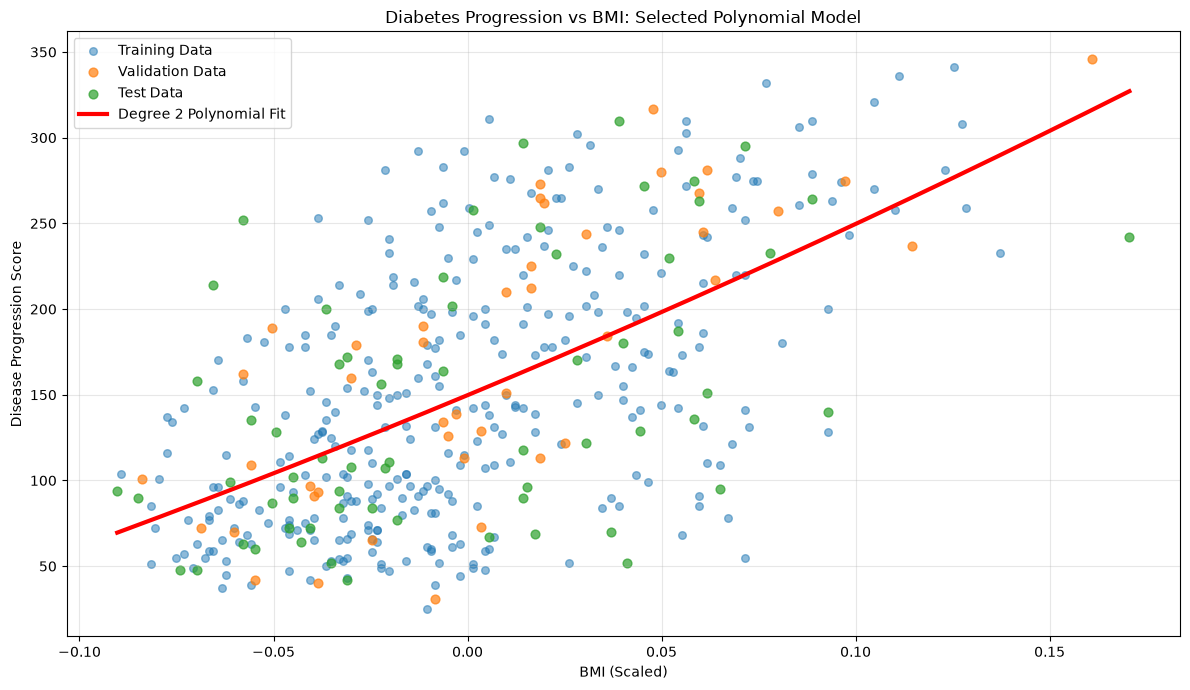

In [14]:

# STEP 10: VISUALIZE THE SELECTED MODEL

# Create a smooth range of BMI values for plotting
bmi_grid = np.linspace(
    X["bmi"].min(),
    X["bmi"].max(),
    300
)

# Convert the grid into a DataFrame
bmi_grid_df = pd.DataFrame(
    {"bmi": bmi_grid}
)

# Predict the fitted curve using our selected model
curve_predictions = best_poly_model.predict(bmi_grid_df)

plt.figure(figsize=(12, 7))

# Training observations
plt.scatter(
    X_train["bmi"],
    y_train,
    label="Training Data",
    alpha=0.5,
    s=30
)

# Validation observations
plt.scatter(
    X_val["bmi"],
    y_val,
    label="Validation Data",
    alpha=0.7,
    s=40
)

# Test observations
plt.scatter(
    X_test["bmi"],
    y_test,
    label="Test Data",
    alpha=0.7,
    s=40
)

# Selected polynomial curve
plt.plot(
    bmi_grid,
    curve_predictions,
    color="red",
    linewidth=3,
    label=f"Degree {best_degree} Polynomial Fit"
)

plt.title("Diabetes Progression vs BMI: Selected Polynomial Model")
plt.xlabel("BMI (Scaled)")
plt.ylabel("Disease Progression Score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



#### Interpretation of Test Performance and Visualization

The selected degree 2 polynomial model achieved the following test results:

- Test R²: 0.215
- Test MAE: 54.842
- Test MAPE: 48.386%

The test R² is lower than the validation R² of 0.523. The test MAE also increased from 47.232 to 54.842.

This suggests that the model did not perform as well on the final test observations as it did on the validation observations.

From the fitted curve, I observed a positive relationship between BMI and disease progression. However, many observations are spread far above and below the curve.

For example, some patients with relatively low scaled BMI have high progression scores, while some patients with higher BMI have much lower scores than the curve predicts.

This tells me that BMI captures part of the overall pattern but cannot accurately explain every patient's disease progression.

The difference between validation and test performance also suggests that the model's results may depend on which observations are included in each dataset.

Since the test set was used only for final evaluation, I will not change the selected model based on these results.


In [15]:
# STEP 11: EXTRACT BEST MODEL EQUATION FROM THE OOP OBJECT

# Our custom class contains an inner Scikit-Learn pipeline at .model
poly_transformer = best_poly_model.model.named_steps["polynomial"]
linear_model = best_poly_model.model.named_steps["regression"]

feature_names = poly_transformer.get_feature_names_out(["bmi"])
coefficients = linear_model.coef_

print("===== BEST MODEL EQUATION =====")
for feature, coefficient in zip(feature_names, coefficients):
    print(f"{feature}: {coefficient:.2f}")

equation = f"y_pred = {coefficients[0]:.2f}"
for feature, coefficient in zip(feature_names[1:], coefficients[1:]):
    sign = "+" if coefficient >= 0 else "-"
    equation += f" {sign} {abs(coefficient):.2f}*({feature})"

print("\nFitted equation:")
print(equation)

===== BEST MODEL EQUATION =====
1: 149.75
bmi: 940.95
bmi^2: 580.17

Fitted equation:
y_pred = 149.75 + 940.95*(bmi) + 580.17*(bmi^2)


In [16]:

# STEP 12: PREDICT DIABETES PROGRESSION

# Choose the median scaled BMI from training data
selected_bmi = X_train["bmi"].median()

# Create input DataFrame
new_patient = pd.DataFrame({
    "bmi": [selected_bmi]
})

# Predict progression
predicted_progression = best_poly_model.predict(new_patient)

print("===== BMI PREDICTION =====")
print(f"Selected scaled BMI: {selected_bmi:.5f}")
print(f"Predicted progression: {predicted_progression[0]:.2f}")


===== BMI PREDICTION =====
Selected scaled BMI: -0.00836
Predicted progression: 141.93


In [17]:
# STEP 13: COUNT TRAINABLE PARAMETERS IN THE OOP OBJECTS

parameter_results = []

for degree, model in poly_models.items():
    transformer = model.model.named_steps["polynomial"]
    regression = model.model.named_steps["regression"]

    generated_features = transformer.get_feature_names_out(["bmi"])
    parameter_results.append({
        "Degree": degree,
        "Generated Features": ", ".join(generated_features),
        "Trainable Parameters": len(regression.coef_)
    })

parameter_table = pd.DataFrame(parameter_results)
print("===== POLYNOMIAL MODEL PARAMETERS =====")
display(parameter_table)

===== POLYNOMIAL MODEL PARAMETERS =====


,Degree,Generated Features,Trainable Parameters
0,0,1,1
1,1,"1, bmi",2
2,2,"1, bmi, bmi^2",3
3,3,"1, bmi, bmi^2, bmi^3",4
4,4,"1, bmi, bmi^2, bmi^3, bmi^4",5
5,5,"1, bmi, bmi^2, bmi^3, bmi^4, bmi^5",6


In [18]:

print("===== PART 2 FINAL RESULTS =====")

print("\n1. SELECTED MODEL")
print("Polynomial Degree:", best_degree)

print("\n2. VALIDATION PERFORMANCE")
print(f"R2: {best_row['Val R2']:.3f}")
print(f"MAE: {best_row['Val MAE']:.3f}")
print(f"MAPE: {best_row['Val MAPE (%)']:.3f}%")

print("\n3. FINAL TEST PERFORMANCE")
print(f"R2: {test_r2:.3f}")
print(f"MAE: {test_mae:.3f}")
print(f"MAPE: {test_mape:.3f}%")

print("\n4. POLYNOMIAL EQUATION")
print(equation)

print("\n5. BMI PREDICTION")
print(f"Scaled BMI: {selected_bmi:.5f}")
print(f"Predicted Progression: {predicted_progression[0]:.2f}")

print("\n6. TRAINABLE PARAMETERS")
display(parameter_table)


===== PART 2 FINAL RESULTS =====

1. SELECTED MODEL
Polynomial Degree: 2

2. VALIDATION PERFORMANCE
R2: 0.523
MAE: 47.232
MAPE: 40.742%

3. FINAL TEST PERFORMANCE
R2: 0.215
MAE: 54.842
MAPE: 48.386%

4. POLYNOMIAL EQUATION
y_pred = 149.75 + 940.95*(bmi) + 580.17*(bmi^2)

5. BMI PREDICTION
Scaled BMI: -0.00836
Predicted Progression: 141.93

6. TRAINABLE PARAMETERS


,Degree,Generated Features,Trainable Parameters
0,0,1,1
1,1,"1, bmi",2
2,2,"1, bmi, bmi^2",3
3,3,"1, bmi, bmi^2, bmi^3",4
4,4,"1, bmi, bmi^2, bmi^3, bmi^4",5
5,5,"1, bmi, bmi^2, bmi^3, bmi^4, bmi^5",6



### 11. Equation of the Selected Polynomial Model

The best model was polynomial regression with degree 2.

Using the coefficients learned from the training data, the fitted equation is:

**Predicted Progression = 149.75 + 940.95(BMI) + 580.17(BMI²)**

In this equation:

- 149.75 is the constant term, representing the predicted score when scaled BMI is zero.
- 940.95 is the coefficient of the linear BMI term.
- 580.17 is the coefficient of the squared BMI term, allowing the relationship to curve.

The BMI values are scaled, so the coefficients should not be interpreted using ordinary BMI units.

Although the equation includes a squared term, the plotted curve has only mild curvature across the observed BMI range.

### 12. BMI Prediction Example

I selected the median BMI value from the training dataset to make an example prediction.

The selected scaled BMI value was -0.00836.

Using the trained model's predict() method, the predicted disease progression score was 141.93.

This example shows how the trained polynomial equation can estimate disease progression for a given scaled BMI value.

However, it is only a statistical prediction. It should not be used as a medical diagnosis or treatment recommendation.

### 13. Trainable Parameters

I also examined the number of trainable parameters for each polynomial model.

- Degree 0: 1 parameter (constant)
- Degree 1: 2 parameters (constant and BMI)
- Degree 2: 3 parameters (constant, BMI and BMI²)
- Degree 3: 4 parameters
- Degree 4: 5 parameters
- Degree 5: 6 parameters

The number of trainable parameters increases because every additional polynomial degree introduces another term with a coefficient that must be learned.

More parameters allow a model to capture more complex relationships. However, they can also increase the risk of overfitting.

In my results, degrees 4 and 5 did not improve validation performance, showing that adding complexity does not automatically produce better predictions.



### 14. Part 2 Conclusion and Limitations

#### Best Model

In Part 2, I compared six polynomial regression models using BMI as the only input feature, with degrees ranging from 0 to 5.

Based on validation R², MAE, and MAPE, I selected the degree 2 polynomial model.

It achieved the best validation performance:

- R²: 0.523
- MAE: 47.232
- MAPE: 40.742%

However, its improvement over the degree 1 model was very small.

#### Training and Validation Behavior

The degree 0 model performed poorly because it predicted a constant value and could not capture the relationship between BMI and progression.

Degrees 1, 2, and 3 performed similarly. Degrees 4 and 5 slightly improved training R² but produced worse validation results.

This suggests that increasing model complexity beyond degree 2 was not beneficial and may have introduced mild overfitting.

The degree 2 model had a training R² of 0.334 and validation R² of 0.523.

Because validation performance was better than training performance, there was no clear evidence of severe training overfitting for the selected model.

#### Final Test Performance

The selected degree 2 model achieved:

- Test R²: 0.215
- Test MAE: 54.842
- Test MAPE: 48.386%

The test results were worse than the validation results.

This suggests that the model has limited ability to generalize consistently across different patient samples.

The validation set was also relatively small, containing 44 observations. Therefore, the validation results may be sensitive to the random split.

#### Where the Model Performs Poorly

The fitted curve shows an overall positive relationship between BMI and disease progression.

However, the patient observations are widely scattered around the curve.

Some patients with relatively low BMI have high progression scores, while others with higher BMI have comparatively low progression scores.

These observations show that the model sometimes underpredicts and sometimes overpredicts disease progression.

The test MAE of 54.842 also indicates that the average absolute prediction error is substantial.

#### Why BMI Alone Is Not Enough

My EDA showed that other features also have meaningful relationships with disease progression.

For example, s5 had a correlation of approximately 0.57 with the target, while blood pressure had a correlation of approximately 0.44.

Using BMI alone ignores information from these additional measurements.

This may explain why the model captures the overall trend but struggles with individual predictions.

#### Model Complexity and Limitations

Higher polynomial degrees did not automatically improve performance.

Degrees 4 and 5 had slightly better training R² but worse validation R² than degree 2.

This demonstrates why model selection should consider unseen-data performance rather than training performance alone.

The dataset also contains only 442 observations, which limits how confidently the results can be generalized to other patient populations.

The R², MAE, and MAPE metrics describe different aspects of prediction error, so interpreting them together gives a more complete picture.

The large test MAPE also shows that the model has considerable relative prediction error.

#### Connection to Previous Workshops

The Performance Metrics workshop taught me that one metric alone may not give a complete picture of model performance.

This is why I compared R², MAE, and MAPE and examined differences between training, validation, and test results.

The kNN workshop emphasized that model complexity, preprocessing, and evaluation on unseen observations affect generalization.

The Logistic Regression workshop helped me understand why the continuous disease progression target requires regression methods unless a separate classification problem is clearly defined.

#### Final Takeaway

The degree 2 polynomial model was the best of the six BMI-only models according to validation results.

However, its test performance was much weaker, showing that BMI alone is not sufficient for highly accurate individual predictions.

In Part 3, I will compare multivariate polynomial regression, decision trees, and kNN regression using all ten input features.

These additional models may capture relationships that a BMI-only model cannot, but their performance must be evaluated using validation data rather than assuming that more features or complexity will always help.

This analysis is educational and does not establish clinical safety or usefulness.


===== TEST ERROR SUMMARY =====
count     66.00
mean      54.84
std       36.74
min        2.32
25%       25.47
50%       47.65
75%       75.10
max      154.82
Name: Absolute Error, dtype: float64

===== FIVE LARGEST PREDICTION ERRORS =====


,BMI,Actual,Predicted,Residual,Absolute Error
78,-0.06,252.0,97.18,154.82,154.82
56,0.04,52.0,189.52,-137.52,137.52
113,0.01,297.0,163.30,133.70,133.70
218,-0.07,214.0,90.62,123.38,123.38
9,0.04,310.0,187.39,122.61,122.61


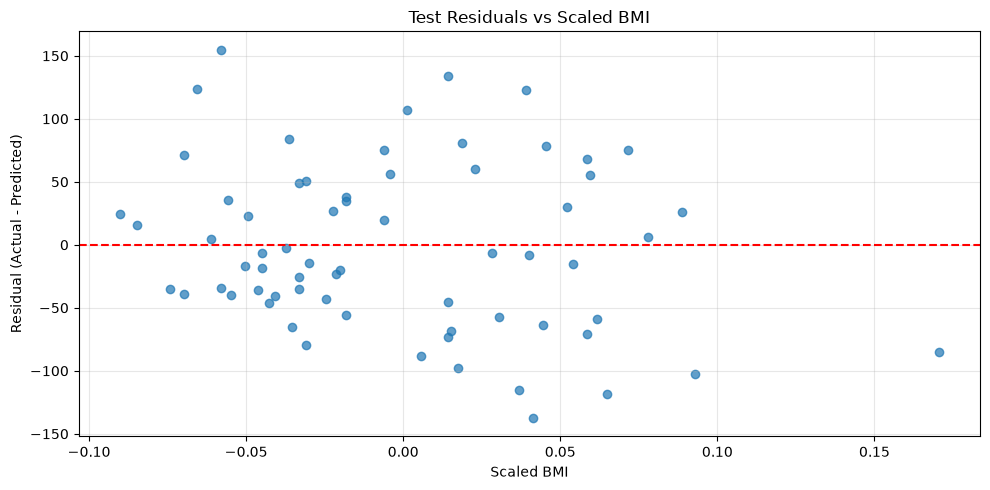

In [19]:

# Extra analysis: Where did our selected model make errors?

error_analysis = pd.DataFrame({
    "BMI": X_test["bmi"],
    "Actual": y_test,
    "Predicted": y_test_pred
})

# Residual = actual minus predicted
error_analysis["Residual"] = (
    error_analysis["Actual"] - error_analysis["Predicted"]
)

# Absolute error ignores whether the prediction was high or low
error_analysis["Absolute Error"] = (
    error_analysis["Residual"].abs()
)

print("===== TEST ERROR SUMMARY =====")
print(
    error_analysis["Absolute Error"]
    .describe()
    .round(2)
)

print("\n===== FIVE LARGEST PREDICTION ERRORS =====")
display(
    error_analysis
    .nlargest(5, "Absolute Error")
    .round(2)
)

# Plot residuals against BMI
plt.figure(figsize=(10, 5))

plt.scatter(
    error_analysis["BMI"],
    error_analysis["Residual"],
    alpha=0.7
)

plt.axhline(0, color="red", linestyle="--")

plt.title("Test Residuals vs Scaled BMI")
plt.xlabel("Scaled BMI")
plt.ylabel("Residual (Actual - Predicted)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



#### Additional Failure Analysis

To better understand where my selected degree 2 polynomial model performs poorly, I examined the prediction errors on the test dataset.

The average absolute prediction error was 54.84 progression-score units.

The largest absolute error was 154.82. For observation index 78, the actual progression score was 252, but the model predicted only 97.18. This was a large underprediction.

For observation index 56, the actual progression score was 52, but the model predicted 189.52. This was an overprediction of 137.52.

For observation index 113, the actual score was 297, but the model predicted 163.30. This was another large underprediction.

These examples show that the model can make substantial errors in both directions.

The residual plot also shows that prediction errors vary across BMI values, with several observations far from the zero-error line.

This supports my earlier conclusion that BMI alone cannot fully explain diabetes progression.

Although BMI has a positive relationship with progression, other patient measurements may contain additional useful information.

Therefore, I believe multivariate models are worth investigating, while remembering that additional features do not automatically guarantee better predictions.



## Part 3 — Multivariate and Non-Parametric Models

### 15. Feature Selection Decision

In Part 2, I used BMI as the only input feature to predict diabetes progression.

My EDA showed that other features also have relationships with the target. For example, s5 had a correlation of approximately 0.57 and blood pressure had a correlation of approximately 0.44.

I also found that some input features are strongly correlated with each other. For example, s1 and s2 had a correlation of approximately 0.90.

However, I do not have enough evidence to conclude that removing any feature would improve prediction performance.

Therefore, I will initially use all ten features in Part 3 and compare the models using training and validation data.

I will continue using the same data split to make the model comparisons consistent.



### 16. Multivariate Polynomial Regression

I will train two multivariate polynomial regression models using all ten input features.

I selected degrees 2 and 3 because both satisfy the assignment requirement to use polynomial degrees greater than 1.

Degree 2 allows squared terms and interactions between features. Degree 3 adds cubic terms and more complex interactions.

I expect higher polynomial degrees to create many additional features, increasing model complexity and the risk of overfitting.

I will compare training and validation R², MAE, and MAPE to determine whether the additional complexity improves predictions.

The test dataset will not be used to select between these models.


In [20]:
# PART 3: MULTIVARIATE POLYNOMIAL REGRESSION WITH OOP

multi_poly_models = {}
multi_poly_results = []

degrees = [2, 3]

for degree in degrees:
    # Create a separate OOP object for this polynomial degree
    model = MultivariatePolynomialModel(degree=degree)
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    # Inspect the fitted polynomial transformer inside our object
    poly = model.model.named_steps["polynomial"]
    n_features = poly.n_output_features_

    multi_poly_results.append({
        "Degree": degree,
        "Polynomial Features": n_features,
        "Train R2": r2_score(y_train, train_pred),
        "Val R2": r2_score(y_val, val_pred),
        "Train MAE": mean_absolute_error(y_train, train_pred),
        "Val MAE": mean_absolute_error(y_val, val_pred),
        "Train MAPE (%)": mean_absolute_percentage_error(
            y_train, train_pred
        ) * 100,
        "Val MAPE (%)": mean_absolute_percentage_error(
            y_val, val_pred
        ) * 100
    })
    multi_poly_models[degree] = model

multi_poly_comparison = pd.DataFrame(multi_poly_results)
print("===== MULTIVARIATE POLYNOMIAL COMPARISON =====")
display(multi_poly_comparison.round(3))

===== MULTIVARIATE POLYNOMIAL COMPARISON =====


,Degree,Polynomial Features,Train R2,Val R2,Train MAE,Val MAE,Train MAPE (%),Val MAPE (%)
0,2,65,0.596,0.436,38.521,48.451,34.321,37.346
1,3,285,0.895,-393.956,17.553,408.496,16.509,335.538


In [21]:

# Compare multivariate models with the BMI-only model

comparison_rows = [{
    "Model": "BMI Polynomial (Degree 2)",
    "Val R2": best_row["Val R2"],
    "Val MAE": best_row["Val MAE"],
    "Val MAPE (%)": best_row["Val MAPE (%)"]
}]

for result in multi_poly_results:
    comparison_rows.append({
        "Model": f"Multivariate Polynomial (Degree {result['Degree']})",
        "Val R2": result["Val R2"],
        "Val MAE": result["Val MAE"],
        "Val MAPE (%)": result["Val MAPE (%)"]
    })

model_comparison = pd.DataFrame(comparison_rows)

print("===== VALIDATION MODEL COMPARISON =====")
display(model_comparison.round(3))


===== VALIDATION MODEL COMPARISON =====


,Model,Val R2,Val MAE,Val MAPE (%)
0,BMI Polynomial (Degree 2),0.523,47.232,40.742
1,Multivariate Polynomial (Degree 2),0.436,48.451,37.346
2,Multivariate Polynomial (Degree 3),-393.956,408.496,335.538



#### Interpretation of Multivariate Polynomial Results

I compared two multivariate polynomial regression models using all ten input features.

**Degree 2 Model**

The degree 2 model generated 65 polynomial features, excluding the intercept.

It achieved a training R² of 0.596 and validation R² of 0.436. Its validation MAE was 48.451, while its validation MAPE was 37.346%.

The decrease from training to validation performance suggests some generalization difficulty, but the model still captures useful relationships.

**Degree 3 Model**

The degree 3 model generated 285 polynomial features, excluding the intercept.

It achieved a high training R² of 0.895 and a low training MAE of 17.553.

However, its validation R² dropped to -393.956, and its validation MAE increased to 408.496.

This is evidence of severe generalization failure. The model may be overfitting the training observations, and the large number of correlated polynomial terms may also cause numerical instability.

**Comparison with BMI-Only Regression**

The BMI-only degree 2 model achieved a validation R² of 0.523 and MAE of 47.232.

The multivariate degree 2 model achieved a lower validation R² of 0.436 and a slightly higher MAE of 48.451. However, its MAPE was lower at 37.346%, compared with 40.742% for the BMI-only model.

This shows that using additional features improved one error metric but not all of them.

**Conclusion**

I consider multivariate degree 2 the better choice among the two multivariate polynomial models because it performed much better on validation data.

The degree 3 model was too complex for this dataset when fitted using ordinary unregularized linear regression.

These results demonstrate that increasing model complexity does not guarantee better predictions on unseen data.

I will continue comparing other regression algorithms using the validation dataset without using the test data for model selection.



### 17. Decision Tree Regression

In this section, I will train two Decision Tree regression models using all ten input features.

Decision Trees make predictions by splitting the data into groups based on feature values.

I will compare two configurations:

- Model 1: max_depth = 3
- Model 2: max_depth = 8

I selected these depths to compare a relatively simple tree with a more flexible tree.

A smaller depth limits the number of decisions the tree can make, while a larger depth allows it to learn more detailed patterns.

I will evaluate both models using training and validation R², MAE, and MAPE.

I will also compare their results to identify possible underfitting or overfitting.


In [22]:
# PART 3: DECISION TREE REGRESSION WITH OOP

tree_models = {}
tree_results = []

depths = [3, 8]

for depth in depths:
    tree_model = DecisionTreeModel(max_depth=depth)
    tree_model.fit(X_train, y_train)

    train_pred = tree_model.predict(X_train)
    val_pred = tree_model.predict(X_val)

    tree_results.append({
        "Max Depth": depth,
        "Train R2": r2_score(y_train, train_pred),
        "Val R2": r2_score(y_val, val_pred),
        "Train MAE": mean_absolute_error(y_train, train_pred),
        "Val MAE": mean_absolute_error(y_val, val_pred),
        "Train MAPE (%)": mean_absolute_percentage_error(
            y_train, train_pred
        ) * 100,
        "Val MAPE (%)": mean_absolute_percentage_error(
            y_val, val_pred
        ) * 100
    })
    tree_models[depth] = tree_model

tree_comparison = pd.DataFrame(tree_results)
print("===== DECISION TREE REGRESSION COMPARISON =====")
display(tree_comparison.round(3))

===== DECISION TREE REGRESSION COMPARISON =====


,Max Depth,Train R2,Val R2,Train MAE,Val MAE,Train MAPE (%),Val MAPE (%)
0,3,0.510,0.527,43.784,47.656,39.034,37.148
1,8,0.898,0.206,15.544,59.250,14.610,50.507



#### Decision Tree Results and Interpretation

I trained two Decision Tree regression models using all ten input features, with maximum depths of 3 and 8.

**Decision Tree with max_depth = 3**

The depth 3 model achieved a training R² of 0.510 and validation R² of 0.527.

Its validation MAE was 47.656 and validation MAPE was 37.148%.

The training and validation R² values were relatively close, suggesting that this simpler tree generalized reasonably well to the validation data.

**Decision Tree with max_depth = 8**

The depth 8 model achieved a much higher training R² of 0.898 and lower training MAE of 15.544.

However, its validation R² dropped to 0.206, while validation MAE increased to 59.250.

This is strong evidence of overfitting. The deeper tree learned more detailed patterns from the training data, but those patterns did not generalize well to validation observations.

**Conclusion**

I selected the depth 3 model as the better Decision Tree because it achieved higher validation R² and lower validation MAE and MAPE.

This experiment helped me understand that higher training accuracy does not necessarily mean a better model.

Increasing tree depth makes a model more flexible, but it can also cause overfitting.

The results support using validation performance to choose model complexity instead of relying only on training results.



### 18. k-Nearest Neighbors (kNN) Regression

In this section, I will train two kNN regression models using all ten input features.

kNN is a non-parametric algorithm that makes predictions based on nearby observations rather than fitting one fixed equation.

For regression, the model predicts a numerical value by averaging the target values of nearby training observations.

I will compare:

- kNN Model 1: k = 3
- kNN Model 2: k = 15

I selected these values to examine how changing the number of neighbors affects model performance.

A smaller k can capture more local patterns but may be sensitive to noise. A larger k produces smoother predictions but may miss important differences between observations.

Since kNN uses distances, feature scaling is important. Although the diabetes features are already scaled, I will use a StandardScaler pipeline fitted only on training data to ensure consistent distance calculations.

I will compare both models using training and validation R², MAE, and MAPE.


In [23]:
# PART 3: K-NEAREST NEIGHBORS REGRESSION WITH OOP

knn_models = {}
knn_results = []

k_values = [3, 15]

for k in k_values:
    knn_model = KNNModel(k=k)
    knn_model.fit(X_train, y_train)

    train_pred = knn_model.predict(X_train)
    val_pred = knn_model.predict(X_val)

    knn_results.append({
        "k": k,
        "Train R2": r2_score(y_train, train_pred),
        "Val R2": r2_score(y_val, val_pred),
        "Train MAE": mean_absolute_error(y_train, train_pred),
        "Val MAE": mean_absolute_error(y_val, val_pred),
        "Train MAPE (%)": mean_absolute_percentage_error(
            y_train, train_pred
        ) * 100,
        "Val MAPE (%)": mean_absolute_percentage_error(
            y_val, val_pred
        ) * 100
    })
    knn_models[k] = knn_model

knn_comparison = pd.DataFrame(knn_results)
print("===== KNN REGRESSION COMPARISON =====")
display(knn_comparison.round(3))

===== KNN REGRESSION COMPARISON =====


,k,Train R2,Val R2,Train MAE,Val MAE,Train MAPE (%),Val MAPE (%)
0,3,0.648,0.287,34.517,54.326,30.038,45.586
1,15,0.507,0.398,43.139,51.561,37.854,41.917



#### kNN Regression Results and Interpretation

I trained two kNN regression models using all ten input features and compared k = 3 and k = 15.

**kNN with k = 3**

The k = 3 model achieved a training R² of 0.648 and validation R² of 0.287.

Its validation MAE was 54.326, and its validation MAPE was 45.586%.

The large difference between training and validation performance suggests that using only three neighbors made the model sensitive to local patterns and potentially caused overfitting.

**kNN with k = 15**

The k = 15 model achieved a training R² of 0.507 and validation R² of 0.398.

Its validation MAE was 51.561, and its validation MAPE was 41.917%.

Although this model had lower training performance, it performed better on validation data.

Using more neighbors created smoother predictions and reduced sensitivity to individual training observations.

**Conclusion**

I selected k = 15 as the better kNN model because it achieved higher validation R² and lower validation MAE and MAPE.

This experiment showed me that improving training performance does not always improve predictions on unseen data.

It also helped me understand how the number of neighbors controls the flexibility of kNN regression.


### 19. Logistic Regression Requirement Review

Our main diabetes target is a numerical progression score, so the main task is regression. Logistic Regression, however, is a classification algorithm.

To explore the professor's Logistic Regression requirement without mixing incompatible evaluation metrics, I implemented two models as a separate binary classification experiment. I defined the categories using the median progression score from the **training set only** and evaluated the models using accuracy, precision, recall, F1-score, and confusion matrices.

The resulting groups are statistical categories and are **not medically validated risk groups**. The classification results are kept separate from the 12 regression models. I requested clarification from my professor about the intended interpretation of this requirement.



#### 19.1 Additional Logistic Regression Classification Experiment

The original diabetes prediction task is a regression problem because the target contains continuous numerical progression scores.

However, the assignment also asks for two Logistic Regression models.

To explore this requirement, I will create a separate binary classification experiment.

I will use the median progression score from the training dataset to divide the target into two categories:

- Class 0: Progression below the training median.
- Class 1: Progression equal to or above the training median.

I will train two Logistic Regression classifiers using different regularization strengths:

- Model 1: C = 0.1
- Model 2: C = 1.0

The C parameter controls regularization strength. Smaller C means stronger regularization.

I will use all ten input features and apply StandardScaler within a pipeline to prevent data leakage.

Since these are classification models, I will evaluate them using accuracy, precision, recall, F1-score, and confusion matrices rather than regression metrics.

The median threshold is only used for this educational classification experiment. It is not a medically validated threshold, and the predicted classes should not be used for clinical decisions.

This experiment is separate from the main regression analysis.


In [24]:
# PART 3: ADDITIONAL LOGISTIC REGRESSION CLASSIFICATION WITH OOP

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Set the threshold using TRAINING targets only
progression_threshold = y_train.median()
y_train_class = (y_train >= progression_threshold).astype(int)
y_val_class = (y_val >= progression_threshold).astype(int)

print("===== CLASSIFICATION TARGET =====")
print("Training median threshold:", progression_threshold)
print("\nTraining class distribution:")
print(y_train_class.value_counts().sort_index())
print("\nValidation class distribution:")
print(y_val_class.value_counts().sort_index())

logistic_models = {}
logistic_results = []

for c_value in [0.1, 1.0]:
    # Create a separate object for each C value
    model = LogisticClassificationModel(C=c_value)
    model.fit(X_train, y_train_class)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    logistic_results.append({
        "C": c_value,
        "Train Accuracy": accuracy_score(y_train_class, train_pred),
        "Val Accuracy": accuracy_score(y_val_class, val_pred),
        "Train Precision": precision_score(
            y_train_class, train_pred, zero_division=0
        ),
        "Val Precision": precision_score(
            y_val_class, val_pred, zero_division=0
        ),
        "Train Recall": recall_score(
            y_train_class, train_pred, zero_division=0
        ),
        "Val Recall": recall_score(
            y_val_class, val_pred, zero_division=0
        ),
        "Train F1": f1_score(
            y_train_class, train_pred, zero_division=0
        ),
        "Val F1": f1_score(
            y_val_class, val_pred, zero_division=0
        )
    })
    logistic_models[c_value] = model

    print(f"\n===== CONFUSION MATRIX: C={c_value} =====")
    print(confusion_matrix(y_val_class, val_pred))

logistic_comparison = pd.DataFrame(logistic_results)
print("\n===== LOGISTIC REGRESSION COMPARISON =====")
display(logistic_comparison.round(3))

===== CLASSIFICATION TARGET =====
Training median threshold: 141.0

Training class distribution:
target
0    165
1    167
Name: count, dtype: int64

Validation class distribution:
target
0    19
1    25
Name: count, dtype: int64

===== CONFUSION MATRIX: C=0.1 =====
[[11  8]
 [ 5 20]]

===== CONFUSION MATRIX: C=1.0 =====
[[ 9 10]
 [ 4 21]]

===== LOGISTIC REGRESSION COMPARISON =====


,C,Train Accuracy,Val Accuracy,Train Precision,Val Precision,Train Recall,Val Recall,Train F1,Val F1
0,0.1,0.756,0.705,0.759,0.714,0.754,0.80,0.757,0.755
1,1.0,0.762,0.682,0.768,0.677,0.754,0.84,0.761,0.750



#### 19.2 Logistic Regression Results and Interpretation

I trained two Logistic Regression classifiers using all ten features and compared regularization values C=0.1 and C=1.0.

For this additional classification experiment, I converted the continuous progression scores into two categories using the training median of 141.

Class 0 represents scores below 141, while Class 1 represents scores equal to or above 141.

These categories are only used for educational analysis and do not represent medically validated risk levels.

**Model 1: Logistic Regression (C=0.1)**

The first model achieved:

- Training Accuracy: 0.756
- Validation Accuracy: 0.705
- Validation Precision: 0.714
- Validation Recall: 0.800
- Validation F1-score: 0.755

The confusion matrix showed 11 true negatives, 20 true positives, 8 false positives, and 5 false negatives.

**Model 2: Logistic Regression (C=1.0)**

The second model achieved:

- Training Accuracy: 0.762
- Validation Accuracy: 0.682
- Validation Precision: 0.677
- Validation Recall: 0.840
- Validation F1-score: 0.750

The confusion matrix showed 9 true negatives, 21 true positives, 10 false positives, and 4 false negatives.

**Model Comparison**

The model with C=0.1 achieved slightly better validation accuracy, precision, and F1-score.

However, C=1.0 achieved higher recall, meaning it identified a slightly larger proportion of actual Class 1 observations.

I selected C=0.1 as the better balanced model for this educational experiment because it performed better on most validation metrics.

The difference was small, and the validation dataset contained only 44 observations, so I cannot conclude that C=0.1 will always perform better on other data.

**Conclusion**

This experiment helped me understand how regularization affects Logistic Regression and why classification requires different evaluation metrics from continuous regression.

The original assignment objective remains predicting numerical progression scores.

Therefore, these Logistic Regression results are presented separately and are not directly compared with the R², MAE, and MAPE results of the regression models.

The interpretation of this additional experiment remains subject to clarification of the assignment requirement.


In [25]:

# MASTER REGRESSION MODEL COMPARISON

all_model_results = []

# 1. BMI polynomial models (degrees 0-5)
for result in poly_results:
    all_model_results.append({
        "Model": f"BMI Polynomial Degree {result['Degree']}",
        **{k: v for k, v in result.items() if k != "Degree"}
    })

# 2. Multivariate polynomial models
for result in multi_poly_results:
    all_model_results.append({
        "Model": f"Multivariate Polynomial Degree {result['Degree']}",
        **{k: v for k, v in result.items()
           if k not in ["Degree", "Polynomial Features"]}
    })

# 3. Decision Tree models
for result in tree_results:
    all_model_results.append({
        "Model": f"Decision Tree Depth {result['Max Depth']}",
        **{k: v for k, v in result.items() if k != "Max Depth"}
    })

# 4. kNN regression models
for result in knn_results:
    all_model_results.append({
        "Model": f"kNN k={result['k']}",
        **{k: v for k, v in result.items() if k != "k"}
    })

# Combine into one DataFrame
master_comparison = pd.DataFrame(all_model_results)

# Rank models by validation MAE (lower is better)
master_comparison = master_comparison.sort_values(
    by="Val MAE",
    ascending=True
).reset_index(drop=True)

print("===== MASTER REGRESSION MODEL COMPARISON =====")
display(master_comparison.round(3))

print("\n===== BEST MODELS BY VALIDATION METRIC =====")

best_r2 = master_comparison.loc[
    master_comparison["Val R2"].idxmax(), "Model"
]

best_mae = master_comparison.loc[
    master_comparison["Val MAE"].idxmin(), "Model"
]

best_mape = master_comparison.loc[
    master_comparison["Val MAPE (%)"].idxmin(), "Model"
]

print("Best Validation R2:", best_r2)
print("Best Validation MAE:", best_mae)
print("Best Validation MAPE:", best_mape)


===== MASTER REGRESSION MODEL COMPARISON =====


,Model,Train R2,Val R2,Train MAE,Val MAE,Train MAPE (%),Val MAPE (%)
0,BMI Polynomial Degree 2,0.334,0.523,51.620,47.232,47.748,40.742
1,BMI Polynomial Degree 3,0.334,0.520,51.651,47.300,47.797,40.904
2,BMI Polynomial Degree 1,0.334,0.522,51.638,47.539,47.762,40.929
3,Decision Tree Depth 3,0.510,0.527,43.784,47.656,39.034,37.148
4,Multivariate Polynomial Degree 2,0.596,0.436,38.521,48.451,34.321,37.346
5,BMI Polynomial Degree 4,0.337,0.506,51.517,48.622,47.520,40.949
6,BMI Polynomial Degree 5,0.337,0.506,51.520,48.628,47.523,40.955
7,kNN k=15,0.507,0.398,43.139,51.561,37.854,41.917
8,kNN k=3,0.648,0.287,34.517,54.326,30.038,45.586
9,Decision Tree Depth 8,0.898,0.206,15.544,59.250,14.610,50.507



===== BEST MODELS BY VALIDATION METRIC =====
Best Validation R2: Decision Tree Depth 3
Best Validation MAE: BMI Polynomial Degree 2
Best Validation MAPE: Decision Tree Depth 3



### 20. Overall Regression Model Comparison

I compared 12 regression models using training and validation results.

The models included six BMI polynomial models, two multivariate polynomial models, two Decision Trees, and two kNN regression models.

#### Best Performing Models

The Decision Tree with max_depth=3 achieved the highest validation R² of 0.527 and the lowest validation MAPE of 37.148%.

The BMI polynomial degree 2 model achieved the lowest validation MAE of 47.232.

The difference between these two models was relatively small.

#### Model Complexity and Overfitting

Some more complex models performed better on training data but worse on validation data.

For example, multivariate polynomial degree 3 achieved a training R² of 0.895 but a validation R² of -393.956.

Similarly, Decision Tree depth 8 achieved a training R² of 0.898 but a validation R² of only 0.206.

These results demonstrate that increasing model complexity can lead to overfitting and poor generalization.

#### kNN Performance

The kNN model with k=15 performed better on validation data than k=3.

This suggests that using more neighbors helped reduce sensitivity to individual training observations.

However, neither kNN model achieved the best overall validation results.

#### Overall Findings

The BMI polynomial degree 2 model and Decision Tree depth 3 were the strongest candidates according to different validation metrics.

The BMI polynomial model had the lowest MAE, while the Decision Tree had the highest R² and lowest MAPE.

Since the metrics did not agree completely, I cannot declare one model the best under every criterion.

The validation set contained only 44 observations, so the ranking may change with a different data split.

Overall, I learned that simpler models can sometimes generalize better than more complex ones and that validation performance is more useful than training performance for model selection.

The test data was not used to choose between the Part 3 models.



### 21. Additional K-Fold Cross-Validation Check

I performed an additional 5-Fold Cross-Validation analysis to understand how consistently selected regression models perform across different groups of training observations.

Although the assignment requires a 75% training, 10% validation, and 15% testing split, I wanted to investigate model stability using multiple training folds.

I compared four regression models:

1. BMI Polynomial Regression (Degree 2)
2. Multivariate Polynomial Regression (Degree 2)
3. Decision Tree Regression (max_depth=3)
4. kNN Regression (k=15)

I used KFold with five splits, shuffle=True, and random_state=42 to make the results reproducible.

For each fold, the model was fitted using four groups and evaluated on the remaining group.

I calculated the mean and standard deviation of R², MAE, and MAPE across the five folds.

I used only the original training data for this additional analysis. The original validation and test datasets were not included.

The purpose of this check is to understand how stable the models are, not to change the previous model-selection decisions based on test performance.


In [26]:
# SECTION 21: 5-FOLD CROSS-VALIDATION OF OOP MODEL PIPELINES

from sklearn.model_selection import KFold, cross_validate

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Pass the internal scikit-learn estimator to cross_validate.
# Scikit-learn clones and refits it separately within each fold.
models_to_check = {
    "BMI Polynomial Degree 2": (
        poly_models[2].model,
        X_train[["bmi"]]
    ),
    "Multivariate Polynomial Degree 2": (
        multi_poly_models[2].model,
        X_train
    ),
    "Decision Tree Depth 3": (
        tree_models[3].model,
        X_train
    ),
    "kNN k=15": (
        knn_models[15].model,
        X_train
    )
}

scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "mape": "neg_mean_absolute_percentage_error"
}

cv_results = []

for name, (model, features) in models_to_check.items():
    scores = cross_validate(
        model,
        features,
        y_train,
        cv=kf,
        scoring=scoring
    )

    r2_scores = scores["test_r2"]
    mae_scores = -scores["test_mae"]
    mape_scores = -scores["test_mape"] * 100

    cv_results.append({
        "Model": name,
        "Mean R2": r2_scores.mean(),
        "R2 Std": r2_scores.std(),
        "Mean MAE": mae_scores.mean(),
        "MAE Std": mae_scores.std(),
        "Mean MAPE (%)": mape_scores.mean(),
        "MAPE Std": mape_scores.std()
    })

cv_comparison = pd.DataFrame(cv_results)
print("===== 5-FOLD CROSS-VALIDATION RESULTS =====")
display(cv_comparison.round(3))

===== 5-FOLD CROSS-VALIDATION RESULTS =====


,Model,Mean R2,R2 Std,Mean MAE,MAE Std,Mean MAPE (%),MAPE Std
0,BMI Polynomial Degree 2,0.298,0.153,52.267,3.442,48.161,7.739
1,Multivariate Polynomial Degree 2,0.246,0.132,51.167,3.172,44.747,3.258
2,Decision Tree Depth 3,0.234,0.144,52.518,2.684,45.827,6.147
3,kNN k=15,0.387,0.082,47.992,0.604,42.113,5.825



#### 21.1 Cross-Validation Results and Interpretation

I performed 5-Fold Cross-Validation on the original training dataset to compare the stability of four regression models.

**BMI Polynomial Regression (Degree 2)**

The model achieved a mean R² of 0.298, mean MAE of 52.267, and mean MAPE of 48.161%.

The R² standard deviation was 0.153, showing some variation in performance between folds.

**Multivariate Polynomial Regression (Degree 2)**

This model achieved a mean R² of 0.246, mean MAE of 51.167, and mean MAPE of 44.747%.

It had the lowest MAPE standard deviation of 3.258 among the four models.

**Decision Tree Regression (Depth 3)**

The Decision Tree achieved a mean R² of 0.234, mean MAE of 52.518, and mean MAPE of 45.827%.

Its performance varied across folds, showing that the results depend partly on which observations are used for training and evaluation.

**kNN Regression (k=15)**

The kNN model achieved the highest mean R² of 0.387, lowest mean MAE of 47.992, and lowest mean MAPE of 42.113%.

It also had the lowest R² standard deviation (0.082) and MAE standard deviation (0.604).

This suggests that kNN with k=15 performed relatively consistently across the five folds.

**Overall Interpretation**

The kNN model with k=15 performed best on average across the three regression metrics in this cross-validation experiment.

However, this ranking was different from the original validation results, where the Decision Tree depth 3 and BMI Polynomial degree 2 models performed strongly.

This shows that model performance can change depending on the observations used for evaluation.

Cross-validation provides additional information about model stability, but it does not guarantee that a model will perform equally well on completely new data.

I used only the original training observations for this check. I did not use the test set for cross-validation or change the previously selected Part 2 model.

The results are useful for understanding generalization, but further evaluation would be needed before making conclusions about clinical usefulness.


### 22. Verification of OOP Model Objects

I verified that the notebook created 14 trained model objects using five external Python classes. Each object's class stores its model settings, and its `fit()` and `predict()` methods are used in the actual experiments.


In [27]:
# VERIFY THAT ALL 14 MODELS ARE OUR CUSTOM OOP OBJECTS
model_groups = {
    "Univariate Polynomial": (poly_models, UnivariatePolynomialModel),
    "Multivariate Polynomial": (multi_poly_models, MultivariatePolynomialModel),
    "Decision Tree": (tree_models, DecisionTreeModel),
    "kNN": (knn_models, KNNModel),
    "Logistic Classification": (logistic_models, LogisticClassificationModel),
}

print("===== OOP MODEL VERIFICATION =====")
total_objects = 0

for name, (objects, expected_class) in model_groups.items():
    assert all(isinstance(obj, expected_class) for obj in objects.values())
    print(f"{name}: {len(objects)} objects of {expected_class.__name__}")
    total_objects += len(objects)

print("Total custom OOP model objects:", total_objects)
assert total_objects == 14
print("All five external classes and 14 objects verified!")


===== OOP MODEL VERIFICATION =====
Univariate Polynomial: 6 objects of UnivariatePolynomialModel
Multivariate Polynomial: 2 objects of MultivariatePolynomialModel
Decision Tree: 2 objects of DecisionTreeModel
kNN: 2 objects of KNNModel
Logistic Classification: 2 objects of LogisticClassificationModel
Total custom OOP model objects: 14
All five external classes and 14 objects verified!



## Final Conclusions

### 1. Project Objective

The objective of this lab was to explore machine learning approaches for predicting diabetes disease progression one year after baseline.

I used the Scikit-Learn Diabetes dataset containing 442 observations and 10 input features.

I performed exploratory data analysis, checked data quality, and divided the dataset into training, validation, and testing groups.

### 2. Data Exploration Findings

My EDA showed that BMI and s5 had relatively strong positive correlations with diabetes progression, at approximately 0.59 and 0.57.

I found no missing values, duplicate rows, or infinite values.

Although the IQR method identified some potential outliers, I kept the observations because there was no evidence that these measurements were incorrect.

### 3. Univariate Polynomial Regression

I trained six polynomial regression models using BMI, with degrees ranging from 0 to 5.

Degree 2 achieved the best validation results:

- R²: 0.523
- MAE: 47.232
- MAPE: 40.742%

Its final test results were:

- R²: 0.215
- MAE: 54.842
- MAPE: 48.386%

The weaker test performance suggests that BMI alone has limited ability to predict individual progression scores accurately.

### 4. Multivariate and Non-Parametric Models

I also compared multivariate polynomial regression, Decision Trees, and kNN regression using all ten features.

The Decision Tree with maximum depth 3 achieved the highest original validation R² of 0.527 and lowest validation MAPE of 37.148%.

However, the BMI Polynomial degree 2 model had the lowest validation MAE of 47.232.

The multivariate polynomial degree 3 model showed severe generalization problems. Its training R² was 0.895, but its validation R² was -393.956.

Similarly, the deeper Decision Tree achieved strong training performance but substantially worse validation performance.

These results showed that more complex models do not necessarily produce better predictions.

### 5. Logistic Regression Experiment

I also implemented two Logistic Regression classifiers as a separate classification experiment.

I converted the continuous progression target into two categories using the training median of 141.

The model with C=0.1 achieved a validation accuracy of 0.705 and F1-score of 0.755.

The model with C=1.0 achieved a validation accuracy of 0.682 and F1-score of 0.750.

I selected C=0.1 based on its slightly better validation accuracy and F1-score, while noting that C=1.0 achieved higher recall.

This experiment was kept separate because classification and regression predict different types of outcomes.

The categories are statistical groupings, not medically validated risk levels. The intended interpretation of the assignment's Logistic Regression requirement still requires confirmation.

### 6. Cross-Validation Findings

I performed an additional 5-Fold Cross-Validation check using the original training observations only.

Among the four models evaluated, kNN with k=15 achieved the strongest average performance:

- Mean R²: 0.387
- Mean MAE: 47.992
- Mean MAPE: 42.113%

It also showed relatively low variability across folds.

The cross-validation ranking differed from the original validation comparison, demonstrating that model performance can be sensitive to how the data is divided.

This analysis was used to investigate stability rather than change the earlier model selection based on test results.

### 7. Limitations

The dataset contains only 442 observations, and some evaluation subsets are relatively small.

The BMI-only model showed considerable prediction error on the test data.

Some complex models also showed strong signs of overfitting or numerical instability.

Although some features are correlated with progression, correlation does not establish causation.

The dataset may not represent all patient populations, and the models have not been clinically validated.

Therefore, the predictions should not be used alone for medical diagnosis, screening decisions, or treatment.

### 8. What I Learned

This lab helped me understand how different machine learning models learn patterns and why evaluation on unseen observations is important.

I learned that:

- Higher training performance does not guarantee better validation performance.
- More features and greater model complexity do not always improve predictions.
- Different evaluation metrics provide different perspectives on model performance.
- Cross-validation helps examine model stability.
- Regression and classification require different target representations and evaluation approaches.
- Preventing data leakage is essential for reliable model evaluation.

Overall, this assignment demonstrated the importance of selecting models carefully, interpreting their limitations, and evaluating predictions responsibly.



## References

1. Scikit-Learn Developers. *Diabetes Dataset Documentation.*
   https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html

2. *Performance Metrics Classification Workshop.*
   https://github.com/UbaidUllah777/PerformanceMetricsClassification

3. *K-Nearest Neighbors Workshop.*
   https://github.com/UbaidUllah777/KNearestNeighbors_Workshop

4. *Logistic Regression Classifier Workshop.*
   https://github.com/UbaidUllah777/LogisticRegressionClassifier_Workshop
